# Statistics Analysis
We can calculate the statistics needed in this notebook through Gephi. This is only used to better visualize some aspects of the networks, primarily the documents' ones obtained from the projections.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import powerlaw
import networkx as nx

designers_address = "graphs\\Projection\\Documents\\designers"
programmers_address = "graphs\\Projection\\Documents\\programmers"

## For Power Law visualization
The Power Law for a network is defined as $$p(k) = C \cdot k^{-\gamma}$$ with $C$ being defined as $$C = \frac {\gamma - 1}{k_{\min}^{-(\gamma - 1)}}$$
The value of $\gamma$ is obtained through the ML model of the powerlaw.

In [ ]:
def find_gamma(df):
    d = df['degree']
    f = d.value_counts()

    data = []
    for deg, freq in zip(d, f):
        data.extend([deg] * freq)

    fit = powerlaw.Fit(data, discrete=True)
    gamma = fit.alpha

    return gamma

In [ ]:
def plot_pk(df, gamma, name):
    # create power law function: P(k) = C * k^(-gamma)
    deg = df['degree']
    deg_uniq = np.unique(deg)
    k_min = deg.min()
    C = (gamma - 1) / (k_min ** (-(gamma - 1)))

    # calculate degree distribution
    freq = df['degree'].value_counts()
    prob = freq / freq.sum()

    # calculate power law
    x_theory = np.logspace(np.log10(k_min), np.log10(deg.max()), 100)
    y_theory = C * x_theory**(-gamma)

    plt.figure(figsize=(8, 6))
    plt.loglog(deg_uniq, prob, 'o', label='Observed', markersize=4)
    plt.loglog(x_theory, y_theory, 'r', label=f'Power law (γ={gamma})', linewidth=2)

    plt.title(f"Degree Distribution - {name}")
    plt.xlabel('Degree (k)')
    plt.xlim(1, 10000)
    plt.ylabel('P(k)')
    plt.ylim(top=1)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


## For Assortativity
Assortativity is obtained through the visualization of the correlation matrix, and then the plotting of the heatmap.

In [ ]:
def to_adjacency_matrix(edges):
    max_sid = edges['Source'].max()
    max_tid = edges['Target'].max()
    max_degree = max(max_sid, max_tid)

    adj_matrix = np.zeros((max_degree + 1, max_degree + 1))
    for _, edge in edges.iterrows():
        s = int(edge['Source'])
        t = int(edge['Target'])
        adj_matrix[s, t] = edge['weight']
        adj_matrix[t, s] = edge['weight']

    return adj_matrix

In [ ]:
def plot_heatmap(matrix, name):
    plt.figure(figsize=(8, 6))
    plt.imshow(matrix, 'viridis')
    plt.colorbar()
    plt.title(f"Correlation Heatmap - {name}")
    plt.xlabel("k_1")
    plt.ylabel("k_2")
    plt.show()


def plot_assortativity(G, name):
    degree_pairs = []
    for u, v in G.edges():
        degree_pairs.append((G.degree(u), G.degree(v)))

    degrees_u, degrees_v = zip(*degree_pairs)

    plt.figure(figsize=(8, 6))
    plt.scatter(degrees_u, degrees_v, alpha=0.5)
    plt.xscale('log')
    plt.yscale('log')

    # obtain log-degrees
    log_degrees_u = np.log10(degrees_u)
    log_degrees_v = np.log10(degrees_v)

    # fit the values of correlations to a polynomial of degree 1
    z = np.polyfit(log_degrees_u, log_degrees_v, 1)
    p = np.poly1d(z)

    x_range = np.logspace(np.log10(min(degrees_u)), np.log10(max(degrees_u)), 100)
    y_fit = 10**(p(np.log10(x_range)))
    plt.plot(x_range, y_fit, '--r', linewidth=2, label=f'$ \\mu $= {nx.degree_assortativity_coefficient(G):.3f}')
    plt.title(f"Correlation Regression - {name}")

    plt.xlabel('k_1')
    plt.ylabel('k_2')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## Designers

### Power Law

In [ ]:
df = pd.read_csv(f"{designers_address}\\designers_doc.csv")
gamma = find_gamma(df)

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 2309/2309 [00:12<00:00, 190.52it/s]


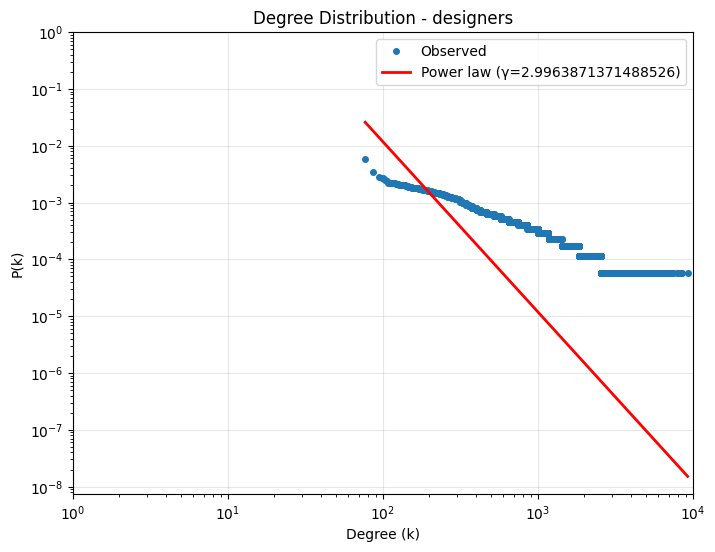

In [ ]:
plot_pk(df, gamma, "designers")

### Assortativity

In [ ]:
nodes = pd.read_csv(f"{designers_address}\\designers_doc.csv")
edges = pd.read_csv(f"{designers_address}\\designers_doc_edges.csv")
adj_matrix = to_adjacency_matrix(edges)

Assortativity Coefficient: -0.1267


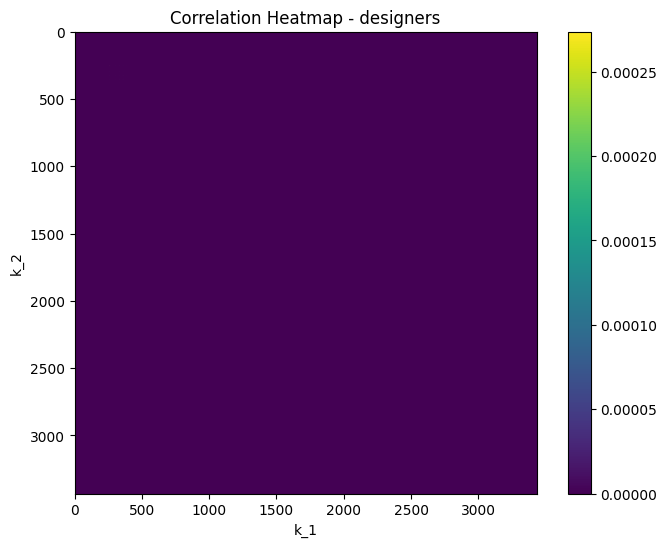

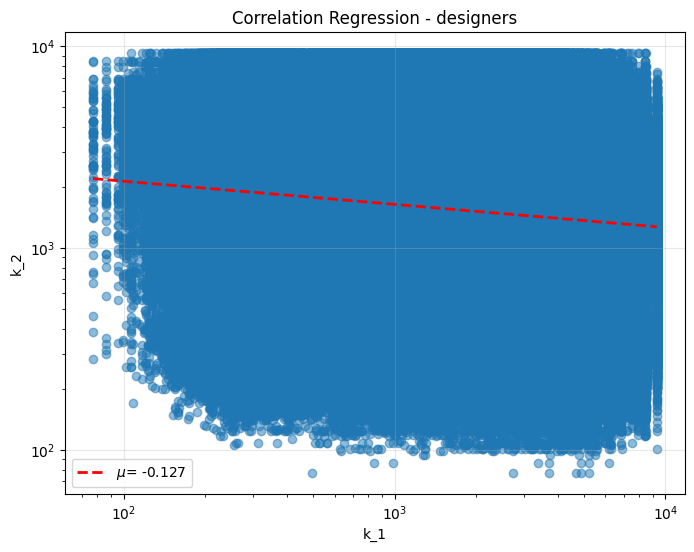

In [ ]:
G = nx.from_numpy_array(adj_matrix)
r = nx.degree_assortativity_coefficient(G)

print(f"Assortativity Coefficient: {r:.4f}")

mm = nx.degree_mixing_matrix(G)
plot_heatmap(mm, "designers")
plot_assortativity(G, "designers")

## Programmers

In [ ]:
df = pd.read_csv(f"{programmers_address}\\programmers_doc.csv")
gamma = find_gamma(df)

Calculating best minimal value for power law fit


Fitting xmin:   0%|          | 0/2389 [00:00<?, ?it/s]

Fitting xmin: 100%|██████████| 2389/2389 [00:18<00:00, 131.43it/s]


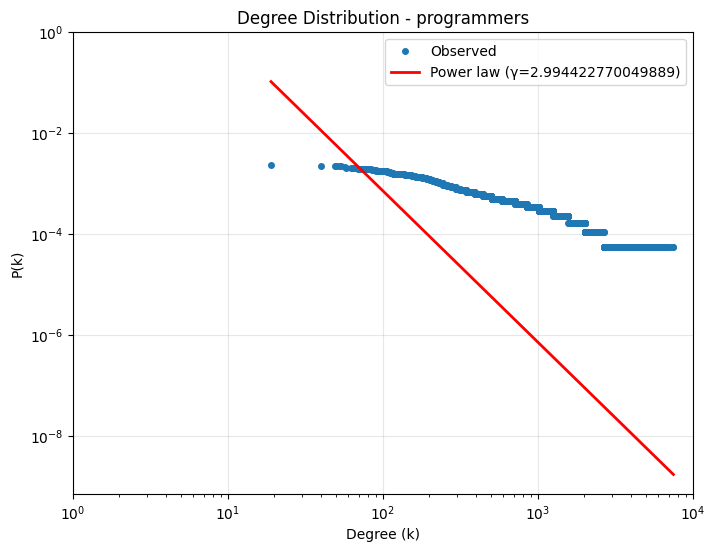

In [ ]:
plot_pk(df, gamma, "programmers")

### Assortativity

In [ ]:
nodes = pd.read_csv(f"{programmers_address}\\programmers_doc.csv")
edges = pd.read_csv(f"{programmers_address}\\programmers_doc_edges.csv")
adj_matrix = to_adjacency_matrix(edges)

Assortativity Coefficient: -0.1045


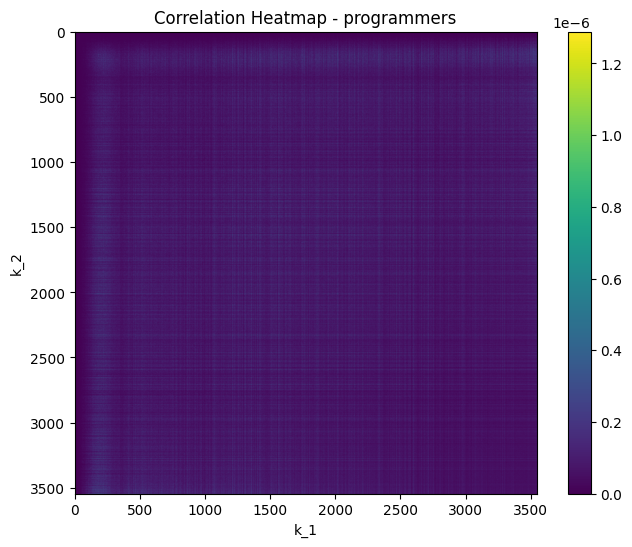

c:\Users\giaco\Documents\python_environments\Network-Science\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


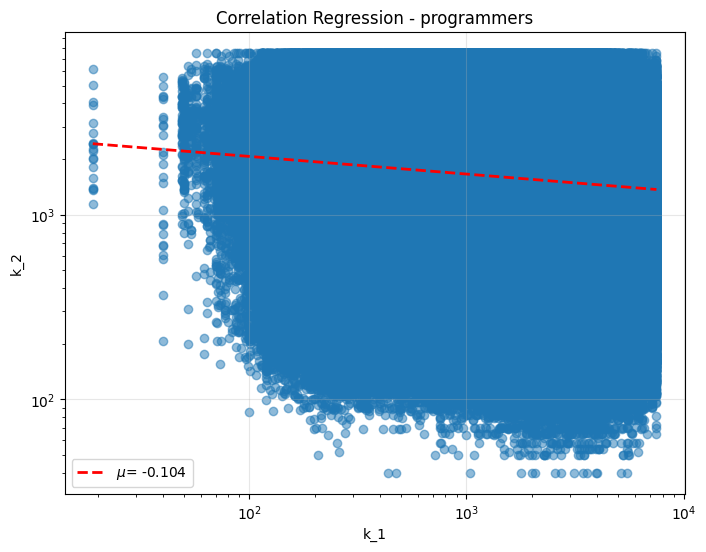

In [ ]:
G = nx.from_numpy_array(adj_matrix)
r = nx.degree_assortativity_coefficient(G)

print(f"Assortativity Coefficient: {r:.4f}")

mm = nx.degree_mixing_matrix(G)
plot_heatmap(mm, "programmers")
plot_assortativity(G, "programmers")